In [3]:
!unzip -q archive.zip -d /content/tomato
!ls /content/tomato

data.yaml  README.dataset.txt  README.roboflow.txt  test  train  valid


In [5]:
import os, glob, time
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Find the train folder
train_dir = [p for p in glob.glob("/content/tomato/**/train", recursive=True) if os.path.isdir(p)][0]

# Find the validation folder (it may be called val, valid, validation or test)
val_dir = None
for name in ["val", "valid", "validation", "test"]:
    found = [p for p in glob.glob(f"/content/tomato/**/{name}", recursive=True) if os.path.isdir(p)]
    if found:
        val_dir = found[0]
        break

print("Train folder:", train_dir)
print("Val folder:", val_dir)
print("GPU:", tf.config.list_physical_devices("GPU"))

In [6]:
IMG_SIZE = (224, 224)   # MobileNetV2 expects 224 x 224 photos
BATCH = 32

if val_dir:   # a separate validation folder exists
    train_ds = keras.utils.image_dataset_from_directory(
        train_dir, image_size=IMG_SIZE, batch_size=BATCH, shuffle=True, seed=42)
    val_ds = keras.utils.image_dataset_from_directory(
        val_dir, image_size=IMG_SIZE, batch_size=BATCH, shuffle=False)
else:         # no validation folder: keep 20% of train aside for testing
    train_ds = keras.utils.image_dataset_from_directory(
        train_dir, image_size=IMG_SIZE, batch_size=BATCH,
        validation_split=0.2, subset="training", seed=42)
    val_ds = keras.utils.image_dataset_from_directory(
        train_dir, image_size=IMG_SIZE, batch_size=BATCH,
        validation_split=0.2, subset="validation", seed=42, shuffle=False)

class_names = train_ds.class_names
num_classes = len(class_names)
print("Classes:", num_classes)
for c in class_names:
    print(" -", c)

Found 645 files belonging to 2 classes.
Found 61 files belonging to 2 classes.
Classes: 2
 - images
 - labels


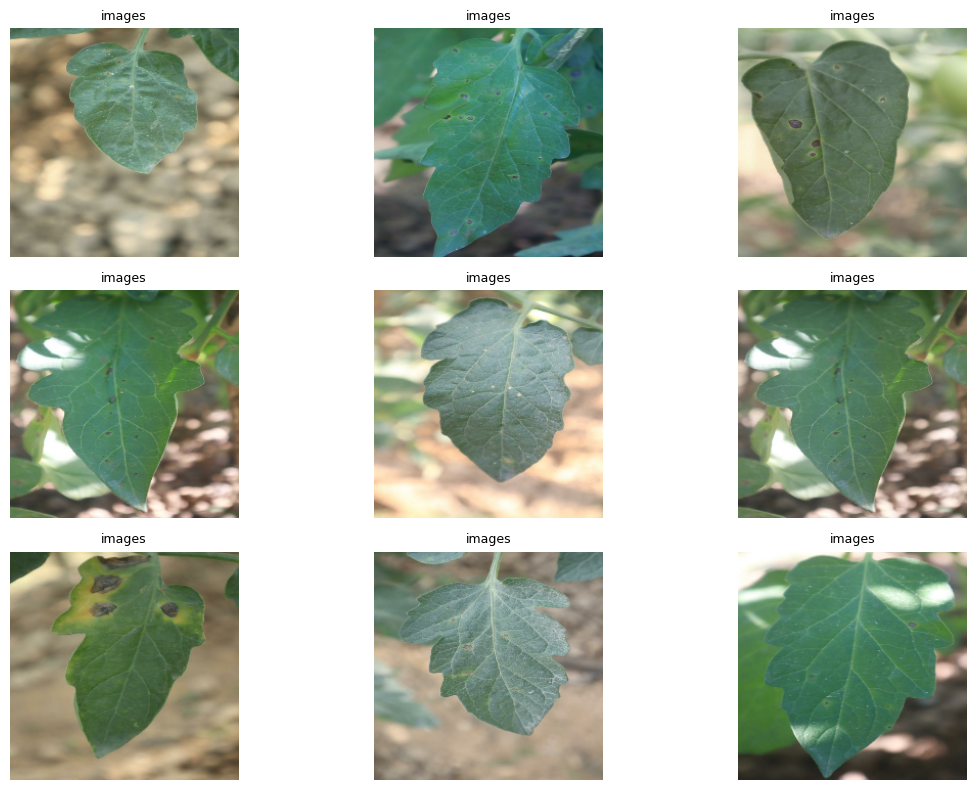

In [7]:
plt.figure(figsize=(12, 8))
for images, labels in train_ds.take(1):
    for i in range(9):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]].replace("Tomato___", ""), fontsize=9)
        plt.axis("off")
plt.tight_layout()
plt.show()

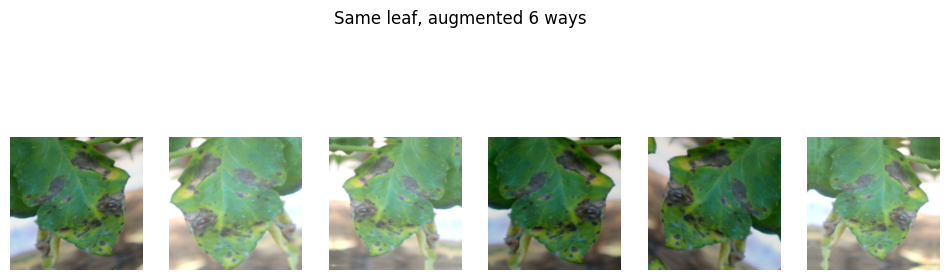

In [8]:
# Randomly change each training photo a little: flip, rotate, zoom, brightness
augment = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomBrightness(0.2),
], name="augmentation")

# Apply augmentation to training photos only (never to test photos)
AUTOTUNE = tf.data.AUTOTUNE
train_ds_aug = train_ds.map(lambda x, y: (augment(x, training=True), y),
                            num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)

# Show one leaf changed 6 different ways
plt.figure(figsize=(12, 4))
for images, _ in train_ds.take(1):
    for i in range(6):
        plt.subplot(1, 6, i + 1)
        plt.imshow(augment(images[:1], training=True)[0].numpy().astype("uint8"))
        plt.axis("off")
plt.suptitle("Same leaf, augmented 6 ways")
plt.show()

In [9]:
# The "already trained doctor": MobileNetV2 trained on ImageNet (1M+ photos)
base = keras.applications.MobileNetV2(input_shape=IMG_SIZE + (3,),
                                      include_top=False,      # remove its old 1000-class answer layer
                                      weights="imagenet")
base.trainable = False   # freeze it: keep what it already knows

inputs = keras.Input(shape=IMG_SIZE + (3,))
x = layers.Rescaling(1./127.5, offset=-1)(inputs)   # pixels 0–255 → -1 to 1 (what MobileNetV2 expects)
x = base(x, training=False)                          # borrowed "eyes"
x = layers.GlobalAveragePooling2D()(x)               # summarise what it saw
x = layers.Dropout(0.2)(x)                           # randomly switch off 20% to avoid memorising
outputs = layers.Dense(num_classes, activation="softmax")(x)   # NEW answer layer: 10 tomato classes

model = keras.Model(inputs, outputs)
model.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])
model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 2)              │         2,562 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,260,546 (8.62 MB)

 Trainable params: 2,562 (10.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [10]:
start = time.time()
history = model.fit(train_ds_aug, validation_data=val_ds, epochs=8)
print(f"Training time: {(time.time() - start)/60:.1f} minutes")

Epoch 1/8
21/21 ━━━━━━━━━━━━━━━━━━━━ 35s 972ms/step - accuracy: 0.9395 - loss: 0.1126 - val_accuracy: 1.0000 - val_loss: 0.0011
Epoch 2/8
21/21 ━━━━━━━━━━━━━━━━━━━━ 19s 386ms/step - accuracy: 1.0000 - loss: 4.1167e-04 - val_accuracy: 1.0000 - val_loss: 4.3640e-04
Epoch 3/8
21/21 ━━━━━━━━━━━━━━━━━━━━ 7s 312ms/step - accuracy: 1.0000 - loss: 2.6908e-04 - val_accuracy: 1.0000 - val_loss: 3.7030e-04
Epoch 4/8
21/21 ━━━━━━━━━━━━━━━━━━━━ 9s 387ms/step - accuracy: 1.0000 - loss: 2.2182e-04 - val_accuracy: 1.0000 - val_loss: 3.5188e-04
Epoch 5/8
21/21 ━━━━━━━━━━━━━━━━━━━━ 10s 386ms/step - accuracy: 1.0000 - loss: 1.9746e-04 - val_accuracy: 1.0000 - val_loss: 3.3891e-04
Epoch 6/8
21/21 ━━━━━━━━━━━━━━━━━━━━ 7s 311ms/step - accuracy: 1.0000 - loss: 2.0822e-04 - val_accuracy: 1.0000 - val_loss: 3.2648e-04
Epoch 7/8
21/21 ━━━━━━━━━━━━━━━━━━━━ 11s 335ms/step - accuracy: 1.0000 - loss: 1.8869e-04 - val_accuracy: 1.0000 - val_loss: 3.1408e-04
Epoch 8/8
21/21 ━━━━━━━━━━━━━━━━━━━━ 8s 385ms/step - accura

In [11]:
# Unfreeze the last 30 layers of MobileNetV2 and train them gently
base.trainable = True
for layer in base.layers[:-30]:
    layer.trainable = False

model.compile(optimizer=keras.optimizers.Adam(1e-5),   # very small steps so we don't destroy what it knows
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

start = time.time()
history_ft = model.fit(train_ds_aug, validation_data=val_ds, epochs=5)
print(f"Fine-tuning time: {(time.time() - start)/60:.1f} minutes")

Epoch 1/5
21/21 ━━━━━━━━━━━━━━━━━━━━ 43s 1s/step - accuracy: 1.0000 - loss: 2.6544e-05 - val_accuracy: 1.0000 - val_loss: 1.8812e-04
Epoch 2/5
21/21 ━━━━━━━━━━━━━━━━━━━━ 8s 341ms/step - accuracy: 1.0000 - loss: 1.2187e-05 - val_accuracy: 1.0000 - val_loss: 1.3937e-04
Epoch 3/5
21/21 ━━━━━━━━━━━━━━━━━━━━ 8s 333ms/step - accuracy: 1.0000 - loss: 1.0847e-05 - val_accuracy: 1.0000 - val_loss: 1.0675e-04
Epoch 4/5
21/21 ━━━━━━━━━━━━━━━━━━━━ 8s 386ms/step - accuracy: 1.0000 - loss: 1.0298e-05 - val_accuracy: 1.0000 - val_loss: 8.2413e-05
Epoch 5/5
21/21 ━━━━━━━━━━━━━━━━━━━━ 9s 325ms/step - accuracy: 1.0000 - loss: 6.4763e-06 - val_accuracy: 1.0000 - val_loss: 6.7469e-05
Fine-tuning time: 1.3 minutes


Validation accuracy: 100.00%


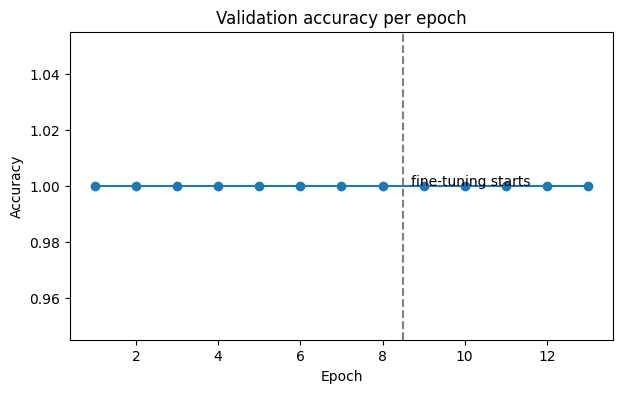

In [12]:
loss, acc = model.evaluate(val_ds, verbose=0)
print(f"Validation accuracy: {acc*100:.2f}%")

acc_curve = history.history["val_accuracy"] + history_ft.history["val_accuracy"]
plt.figure(figsize=(7, 4))
plt.plot(range(1, len(acc_curve) + 1), acc_curve, marker="o")
plt.axvline(len(history.history["val_accuracy"]) + 0.5, linestyle="--", color="gray")
plt.text(len(history.history["val_accuracy"]) + 0.7, min(acc_curve), "fine-tuning starts")
plt.title("Validation accuracy per epoch")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.show()

In [14]:
# Print every folder that has photos in it, and how many
for root, dirs, files in os.walk("/content/tomato"):
    imgs = [f for f in files if f.lower().endswith((".jpg", ".jpeg", ".png"))]
    if imgs:
        print(f"{len(imgs):5d} photos  →  {root}")

print("\nClass names the model used:", class_names)
print("Train folder used:", train_dir)
print("Val folder used:", val_dir)

  645 photos  →  /content/tomato/train/images
   31 photos  →  /content/tomato/test/images
   61 photos  →  /content/tomato/valid/images

Class names the model used: ['images', 'labels']
Train folder used: /content/tomato/train
Val folder used: /content/tomato/valid


In [15]:
import kagglehub

# Download the 10-class tomato leaf dataset from Kaggle
path = kagglehub.dataset_download("kaustubhb999/tomatoleaf")
print("Downloaded to:", path)

# Show every folder that has photos, and how many
import os
for root, dirs, files in os.walk(path):
    imgs = [f for f in files if f.lower().endswith((".jpg", ".jpeg", ".png"))]
    if imgs:
        print(f"{len(imgs):5d} photos  →  {root}")

Using Colab cache for faster access to the 'tomatoleaf' dataset.
Downloaded to: /kaggle/input/tomatoleaf
  100 photos  →  /kaggle/input/tomatoleaf/tomato/val/Tomato___Late_blight
  100 photos  →  /kaggle/input/tomatoleaf/tomato/val/Tomato___healthy
  100 photos  →  /kaggle/input/tomatoleaf/tomato/val/Tomato___Early_blight
  100 photos  →  /kaggle/input/tomatoleaf/tomato/val/Tomato___Septoria_leaf_spot
  100 photos  →  /kaggle/input/tomatoleaf/tomato/val/Tomato___Tomato_Yellow_Leaf_Curl_Virus
  100 photos  →  /kaggle/input/tomatoleaf/tomato/val/Tomato___Bacterial_spot
  100 photos  →  /kaggle/input/tomatoleaf/tomato/val/Tomato___Target_Spot
  100 photos  →  /kaggle/input/tomatoleaf/tomato/val/Tomato___Tomato_mosaic_virus
  100 photos  →  /kaggle/input/tomatoleaf/tomato/val/Tomato___Leaf_Mold
  100 photos  →  /kaggle/input/tomatoleaf/tomato/val/Tomato___Spider_mites Two-spotted_spider_mite
 1000 photos  →  /kaggle/input/tomatoleaf/tomato/train/Tomato___Late_blight
 1000 photos  →  /kaggl

In [16]:
import glob
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import numpy as np
import matplotlib.pyplot as plt
import time

# Find the train and val folders inside the Kaggle download
train_dir = [p for p in glob.glob(f"{path}/**/train", recursive=True) if os.path.isdir(p)][0]
val_dir   = [p for p in glob.glob(f"{path}/**/val",   recursive=True) if os.path.isdir(p)][0]
print("Train folder:", train_dir)
print("Val folder:", val_dir)

IMG_SIZE = (224, 224)   # MobileNetV2 expects 224 x 224 photos
BATCH = 32

train_ds = keras.utils.image_dataset_from_directory(
    train_dir, image_size=IMG_SIZE, batch_size=BATCH, shuffle=True, seed=42)
val_ds = keras.utils.image_dataset_from_directory(
    val_dir, image_size=IMG_SIZE, batch_size=BATCH, shuffle=False)

class_names = train_ds.class_names
num_classes = len(class_names)
print("\nNumber of classes:", num_classes)
for c in class_names:
    print(" -", c)

Train folder: /kaggle/input/tomatoleaf/tomato/train
Val folder: /kaggle/input/tomatoleaf/tomato/val
Found 10000 files belonging to 10 classes.
Found 1000 files belonging to 10 classes.

Number of classes: 10
 - Tomato___Bacterial_spot
 - Tomato___Early_blight
 - Tomato___Late_blight
 - Tomato___Leaf_Mold
 - Tomato___Septoria_leaf_spot
 - Tomato___Spider_mites Two-spotted_spider_mite
 - Tomato___Target_Spot
 - Tomato___Tomato_Yellow_Leaf_Curl_Virus
 - Tomato___Tomato_mosaic_virus
 - Tomato___healthy


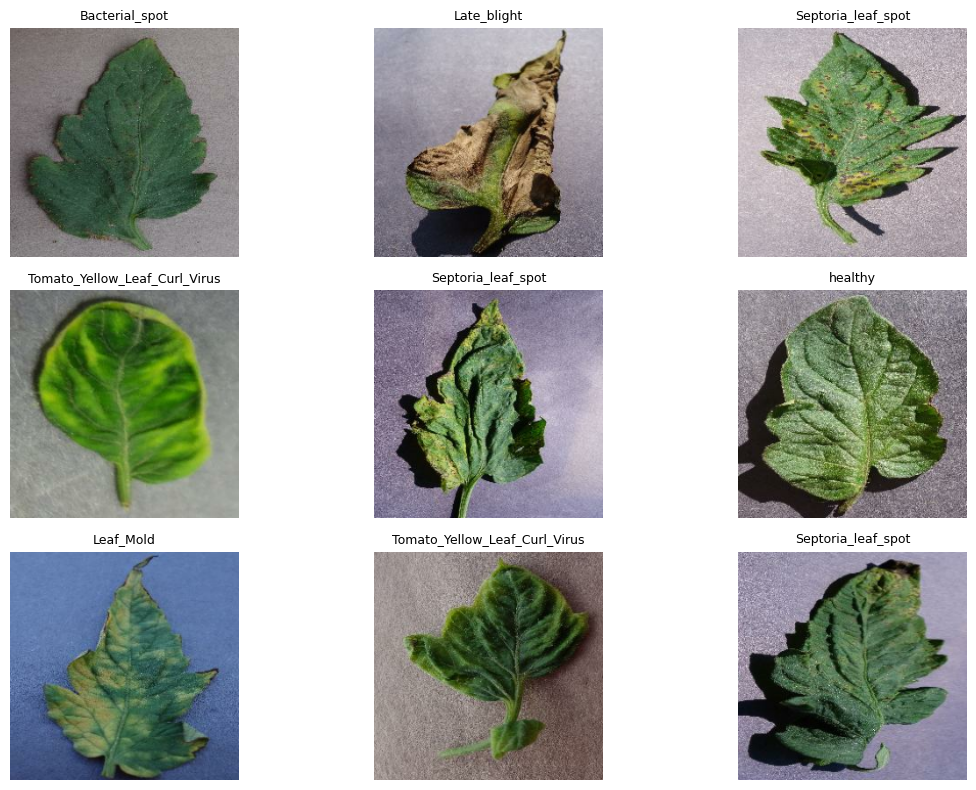

In [17]:
plt.figure(figsize=(12, 8))
for images, labels in train_ds.take(1):          # take 1 batch of 32 photos
    for i in range(9):                           # show the first 9
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]].replace("Tomato___", ""), fontsize=9)
        plt.axis("off")
plt.tight_layout()
plt.show()

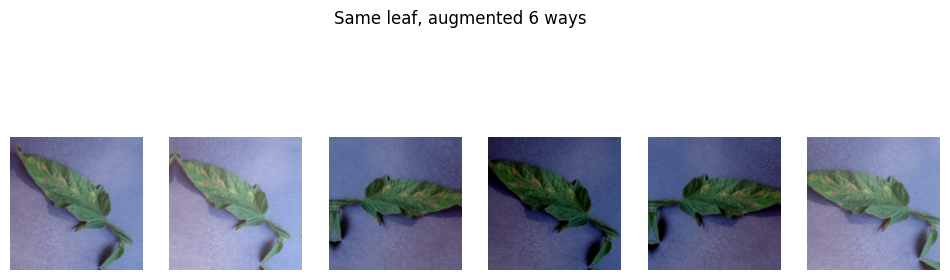

In [18]:
# Randomly change each training photo a little
augment = keras.Sequential([
    layers.RandomFlip("horizontal"),   # flip left ↔ right
    layers.RandomRotation(0.1),        # rotate a little (up to ~36°)
    layers.RandomZoom(0.1),            # zoom in/out up to 10%
    layers.RandomBrightness(0.2),      # make brighter or darker up to 20%
], name="augmentation")

# Apply augmentation to TRAINING photos only (never to test photos)
AUTOTUNE = tf.data.AUTOTUNE
train_ds_aug = train_ds.map(lambda x, y: (augment(x, training=True), y),
                            num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)

# Show ONE leaf changed 6 different ways
plt.figure(figsize=(12, 4))
for images, _ in train_ds.take(1):
    for i in range(6):
        plt.subplot(1, 6, i + 1)
        plt.imshow(augment(images[:1], training=True)[0].numpy().astype("uint8"))
        plt.axis("off")
plt.suptitle("Same leaf, augmented 6 ways")
plt.show()

In [19]:
# 1. Borrow the "already trained doctor": MobileNetV2, trained on 1M+ ImageNet photos
base = keras.applications.MobileNetV2(input_shape=IMG_SIZE + (3,),
                                      include_top=False,      # remove its old answer layer (1000 everyday objects)
                                      weights="imagenet")     # keep everything it already learned
base.trainable = False   # freeze it: don't change what it already knows

# 2. Build our model around it
inputs = keras.Input(shape=IMG_SIZE + (3,))                   # a 224 x 224 colour photo
x = layers.Rescaling(1./127.5, offset=-1)(inputs)            # pixels 0–255 → -1 to 1 (what MobileNetV2 expects)
x = base(x, training=False)                                  # the borrowed "eyes" look at the leaf
x = layers.GlobalAveragePooling2D()(x)                       # summarise what it saw into one list
x = layers.Dropout(0.2)(x)                                   # randomly switch off 20% → avoids memorising
outputs = layers.Dense(num_classes, activation="softmax")(x) # NEW answer layer: 10 tomato classes

model = keras.Model(inputs, outputs)

# 3. How it learns
model.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])
model.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │        12,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,270,794 (8.66 MB)

 Trainable params: 12,810 (50.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [20]:
start = time.time()

history = model.fit(
    train_ds_aug,               # augmented training photos
    validation_data=val_ds,     # real test photos to check progress
    epochs=8                    # look at all photos 8 times
)

print(f"\nTraining time: {(time.time() - start)/60:.1f} minutes")

Epoch 1/8
313/313 ━━━━━━━━━━━━━━━━━━━━ 153s 457ms/step - accuracy: 0.6537 - loss: 1.0362 - val_accuracy: 0.7670 - val_loss: 0.7081
Epoch 2/8
313/313 ━━━━━━━━━━━━━━━━━━━━ 109s 347ms/step - accuracy: 0.7987 - loss: 0.6058 - val_accuracy: 0.7810 - val_loss: 0.6330
Epoch 3/8
313/313 ━━━━━━━━━━━━━━━━━━━━ 110s 351ms/step - accuracy: 0.8278 - loss: 0.5158 - val_accuracy: 0.8100 - val_loss: 0.5542
Epoch 4/8
313/313 ━━━━━━━━━━━━━━━━━━━━ 108s 343ms/step - accuracy: 0.8456 - loss: 0.4617 - val_accuracy: 0.8380 - val_loss: 0.4966
Epoch 5/8
313/313 ━━━━━━━━━━━━━━━━━━━━ 108s 344ms/step - accuracy: 0.8528 - loss: 0.4302 - val_accuracy: 0.8440 - val_loss: 0.4775
Epoch 6/8
313/313 ━━━━━━━━━━━━━━━━━━━━ 144s 350ms/step - accuracy: 0.8615 - loss: 0.4110 - val_accuracy: 0.8330 - val_loss: 0.5044
Epoch 7/8
313/313 ━━━━━━━━━━━━━━━━━━━━ 110s 352ms/step - accuracy: 0.8640 - loss: 0.4021 - val_accuracy: 0.8310 - val_loss: 0.5063
Epoch 8/8
313/313 ━━━━━━━━━━━━━━━━━━━━ 111s 353ms/step - accuracy: 0.8711 - loss: 0

In [21]:
# 1. Unfreeze the doctor, but only the LAST 30 layers
base.trainable = True
for layer in base.layers[:-30]:      # all layers EXCEPT the last 30...
    layer.trainable = False          # ...stay frozen

# 2. Learn with VERY small steps
model.compile(optimizer=keras.optimizers.Adam(1e-5),   # 100x smaller than before!
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

# 3. Train a bit more
start = time.time()
history_ft = model.fit(train_ds_aug, validation_data=val_ds, epochs=5)
print(f"\nFine-tuning time: {(time.time() - start)/60:.1f} minutes")

Epoch 1/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 142s 398ms/step - accuracy: 0.6819 - loss: 1.3072 - val_accuracy: 0.8540 - val_loss: 0.4508
Epoch 2/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 120s 352ms/step - accuracy: 0.8354 - loss: 0.4846 - val_accuracy: 0.8780 - val_loss: 0.3836
Epoch 3/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 110s 349ms/step - accuracy: 0.8574 - loss: 0.4126 - val_accuracy: 0.8840 - val_loss: 0.3593
Epoch 4/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 144s 354ms/step - accuracy: 0.8725 - loss: 0.3603 - val_accuracy: 0.8800 - val_loss: 0.3415
Epoch 5/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 110s 349ms/step - accuracy: 0.8869 - loss: 0.3323 - val_accuracy: 0.8830 - val_loss: 0.3302

Fine-tuning time: 10.4 minutes


Final validation accuracy: 88.30%


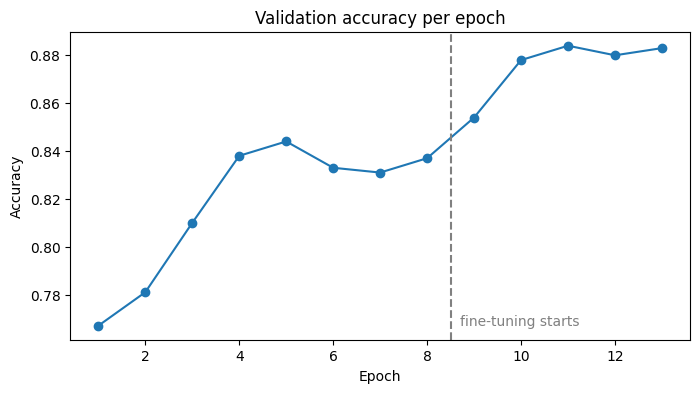

In [22]:
# Final score on the 1,000 test photos
loss, acc = model.evaluate(val_ds, verbose=0)
print(f"Final validation accuracy: {acc*100:.2f}%")

# Join the two training stages into one line
acc_curve = history.history["val_accuracy"] + history_ft.history["val_accuracy"]
stage1 = len(history.history["val_accuracy"])

plt.figure(figsize=(8, 4))
plt.plot(range(1, len(acc_curve) + 1), acc_curve, marker="o")
plt.axvline(stage1 + 0.5, linestyle="--", color="gray")          # line where fine-tuning starts
plt.text(stage1 + 0.7, min(acc_curve), "fine-tuning starts", color="gray")
plt.title("Validation accuracy per epoch")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.show()

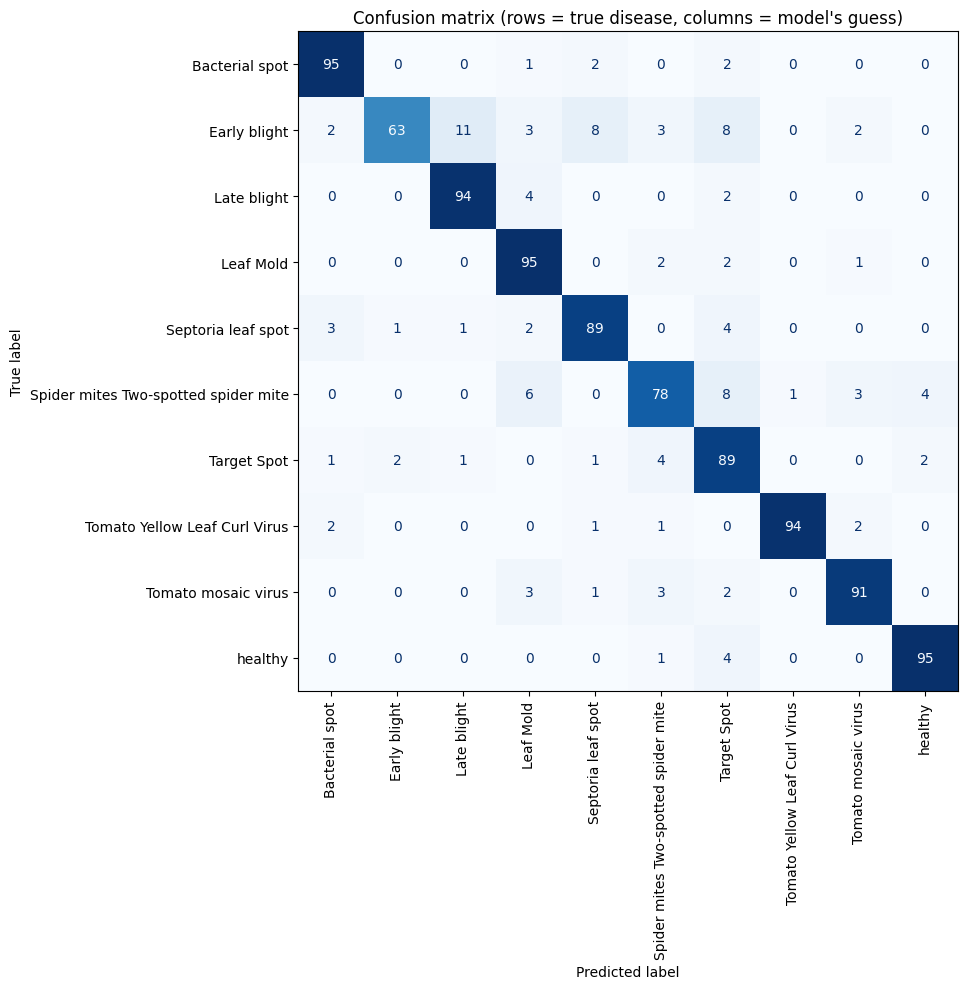

                                      precision    recall  f1-score   support

                      Bacterial spot      0.922     0.950     0.936       100
                        Early blight      0.955     0.630     0.759       100
                         Late blight      0.879     0.940     0.908       100
                           Leaf Mold      0.833     0.950     0.888       100
                  Septoria leaf spot      0.873     0.890     0.881       100
Spider mites Two-spotted spider mite      0.848     0.780     0.812       100
                         Target Spot      0.736     0.890     0.805       100
       Tomato Yellow Leaf Curl Virus      0.989     0.940     0.964       100
                 Tomato mosaic virus      0.919     0.910     0.915       100
                             healthy      0.941     0.950     0.945       100

                            accuracy                          0.883      1000
                           macro avg      0.889     0.883     

In [23]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

# 1. The real answers for all 1,000 test photos
y_true = np.concatenate([y.numpy() for _, y in val_ds])

# 2. The model's guesses (pick the class with the highest %)
y_pred = np.argmax(model.predict(val_ds, verbose=0), axis=1)

# 3. Shorter names for the chart
short = [c.replace("Tomato___", "").replace("_", " ") for c in class_names]

# 4. Draw the 10 x 10 report card
fig, ax = plt.subplots(figsize=(10, 10))
ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred), display_labels=short).plot(
    ax=ax, xticks_rotation=90, colorbar=False, cmap="Blues")
plt.title("Confusion matrix (rows = true disease, columns = model's guess)")
plt.tight_layout()
plt.show()

# 5. Score for each disease
print(classification_report(y_true, y_pred, target_names=short, digits=3))

## Classification report
- Overall accuracy: 88.3% (1,000 test images, 100 per class).
- Best classes: Yellow Leaf Curl Virus (F1 0.964), healthy (0.945), Bacterial spot (0.936).
- Weakest class: Early blight, recall 0.63. The model is precise when it predicts Early blight (0.955) but misses 37% of cases, likely confusing it with other diseases that also show brown spots (Late blight, Target Spot, Septoria).
- Target Spot has the lowest precision (0.736): other diseases are sometimes wrongly labelled as Target Spot.
- Next steps: longer fine-tuning, unfreezing more layers, or a larger model (EfficientNet/ResNet50) to better separate the brown-spot diseases.